
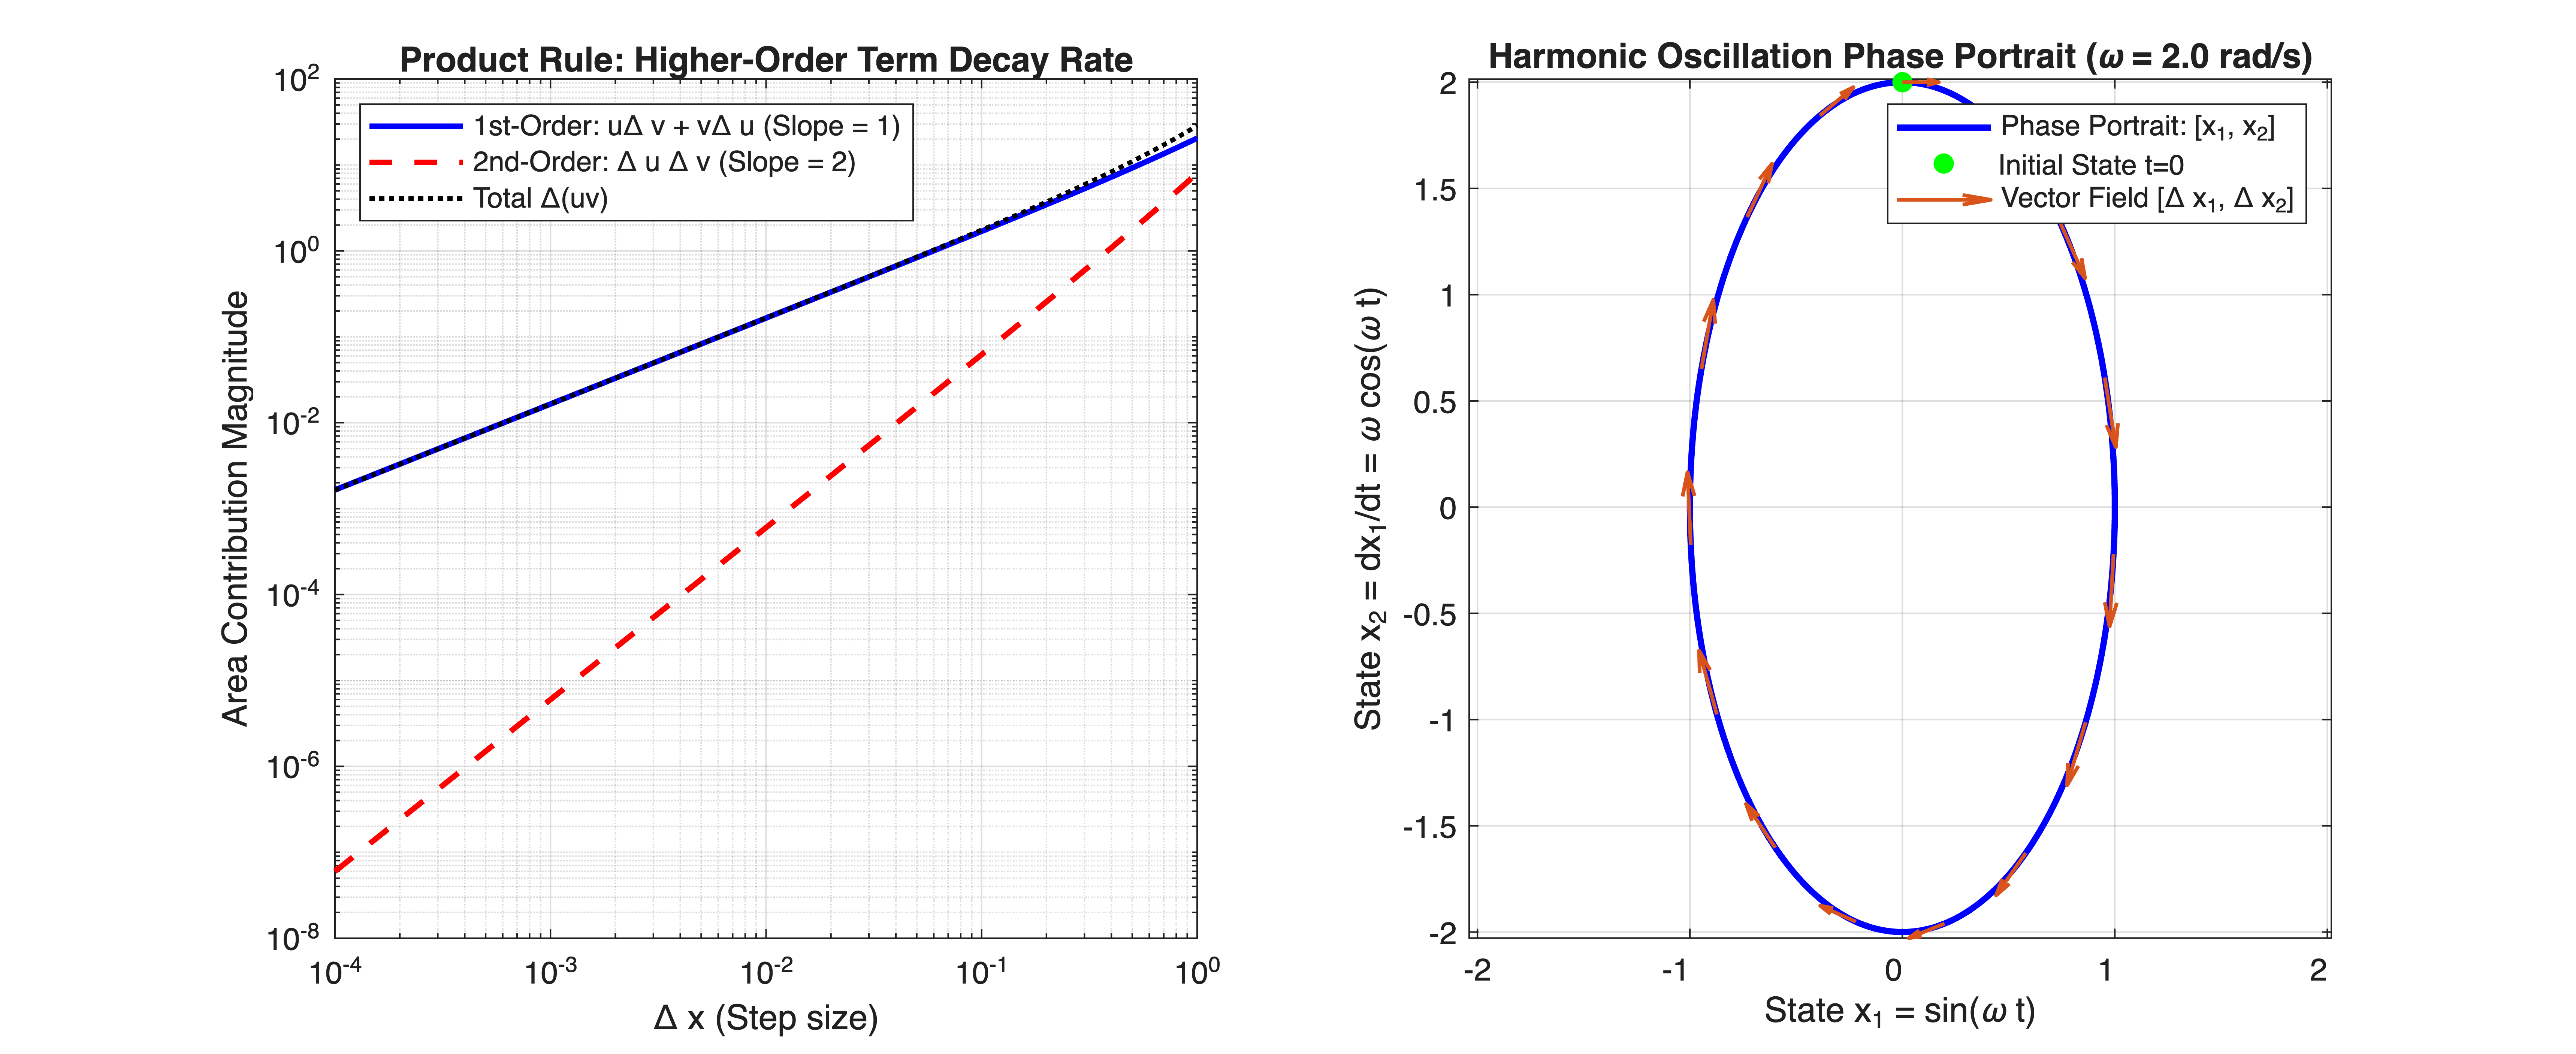

In [1]:
%% MIT 18.01 Lecture 3: Product Rule Geometry & Trig Harmonic Trajectory
% Mathematical Tool Application: Used for state coupling derivation,
% Lyapunov candidate function differentiation, and harmonic state-space evolution.


clear; clc; close all;


%% Part 1: Geometric Breakdown of Product Rule Increment
% Define base states: u(x) = x^2, v(x) = 2*x + 1 at x0 = 1.5
u_func = @(x) x.^2;
v_func = @(x) 2*x + 1;


x0 = 1.5;
u0 = u_func(x0);
v0 = v_func(x0);


% Varying step size Delta x to observe area convergence
dx_sweep = logspace(-4, 0, 50);
delta_u = u_func(x0 + dx_sweep) - u0;
delta_v = v_func(x0 + dx_sweep) - v0;


total_delta_area = (u0 + delta_u) .* (v0 + delta_v) - (u0 * v0);
first_order_terms = u0 * delta_v + v0 * delta_u;
second_order_term = delta_u .* delta_v;


figure('Color', 'w', 'Position', [100, 100, 1100, 450]);


subplot(1, 2, 1);
loglog(dx_sweep, abs(first_order_terms), 'b-', 'LineWidth', 1.8, 'DisplayName', '1st-Order: u\Delta v + v\Delta u (Slope = 1)'); hold on;
loglog(dx_sweep, abs(second_order_term), 'r--', 'LineWidth', 1.8, 'DisplayName', '2nd-Order: \Delta u \Delta v (Slope = 2)');
loglog(dx_sweep, abs(total_delta_area), 'k:', 'LineWidth', 1.5, 'DisplayName', 'Total \Delta(uv)');
grid on;
xlabel('\Delta x (Step size)');
ylabel('Area Contribution Magnitude');
title('Product Rule: Higher-Order Term Decay Rate');
legend('Location', 'northwest');
%% Part 2: Trigonometric Derivative Dynamics & Phase Portrait
% Harmonic system: x1(t) = sin(omega*t), x2(t) = dx1/dt = omega*cos(omega*t)
omega = 2.0; % Angular frequency (rad/s)
t_span = linspace(0, 2*pi/omega, 300);


x1 = sin(omega * t_span);
x2 = omega * cos(omega * t_span); % First derivative via trig rule
x1_dot_analytic = -omega^2 * sin(omega * t_span); % Second derivative


subplot(1, 2, 2);
plot(x1, x2, 'b-', 'LineWidth', 2, 'DisplayName', 'Phase Portrait: [x_1, x_2]'); hold on;
plot(x1(1), x2(1), 'go', 'MarkerFaceColor', 'g', 'DisplayName', 'Initial State t=0');


% Direction vector arrows along trajectory
quiver(x1(1:20:end), x2(1:20:end), ...
    x2(1:20:end), x1_dot_analytic(1:20:end), ...
    0.3, 'Color', [0.85, 0.33, 0.1], 'LineWidth', 1.2, 'DisplayName', 'Vector Field [\Delta x_1, \Delta x_2]');


grid on;
axis equal;
xlabel('State x_1 = sin(\omega t)');
ylabel('State x_2 = dx_1/dt = \omega cos(\omega t)');
title(sprintf('Harmonic Oscillation Phase Portrait (\\omega = %.1f rad/s)', omega));
legend('Location', 'northeast');